# Part 2, Topic 1, Lab B (Explorer): Password Bypass - Edit, Run, Watch

---
NOTE: This lab references some (commercial) training material on [ChipWhisperer.io](https://www.ChipWhisperer.io). You can freely execute and use the lab per the open-source license (including using it in your own courses if you distribute similarly), but you must maintain notice about this source location. Consider joining our training course to enjoy the full experience.

---

**SUMMARY:** *In Lab 2_1B you recover a password by watching a chip's power. This **Explorer** notebook is the "why" companion: you change the numbers yourself - which traces to compare, how to score them, how many to average, how much noise to add - and watch the results change, so you can see exactly why the attack works and what would stop it.*

**LEARNING OUTCOMES:**

* See that a wrong guess and a right guess take different paths - and find the exact sample where the two traces split
* Measure how much later that split moves for every extra correct character (in samples)
* Score every possible character and see which one stands out - and how the window, the scoring method and averaging change the picture
* Run the whole attack round by round and count how many guesses it needs compared with brute force
* Find out what breaks the attack (noise, a poorly chosen window, random delays) and what fixes it - averaging, a sensible window, re-alignment

## How this notebook works

Every code cell that you are meant to change starts with the line **`# ✏️ EDIT THESE`**. The recipe is always the same:

1. **Read** the short explanation above the cell.
2. **Change** one of the numbers in the ✏️ block.
3. Press **Shift + Enter** to run the cell and **watch the plot and the printed numbers change**.
4. Change it again. Break it on purpose - you cannot hurt anything. If you get lost, use **Kernel > Restart & Run All**.

| Steps | What you do | Needs hardware? |
|---|---|---|
| 1 - 4 | Look at the traces, find where they split, score the characters, run the whole attack. | **No** - recorded traces by default (or your own chip with `VERSION = 'HARDWARE'`) |
| 5 - 6 | Break the attack with noise and with random delays, then fix it. | No (model built from real traces) |
| 7 | Run everything on your own chip. | **Yes** |
| 8 | Check your understanding. | No |

Quick keys: **Shift+Enter** run the cell and move on  |  **Ctrl+Enter** run and stay  |  **Esc, then A / B** insert a cell above / below.

## Prerequisites

* ☑ **Lab 0 - SCA101 Setup** passed.
* ☑ Jupyter basics: you can run a cell.
* (Recommended) **Lab 2_1A - Instruction Power Explorer** - the same ideas (samples, clock cycles, repeating patterns) are used here.
* (Optional) **Lab 2_1B (MAIN)** - you can do it before or after this notebook.

## Setup

Run the next two cells and wait for `✔️ Ready!`.

* `VERSION = 'SIMULATED'` - use the recorded traces from the `cwtraces` package (default). No hardware needed.
* `VERSION = 'HARDWARE'` - connect to your ChipWhisperer, build and flash the `basic-passwdcheck` firmware, and capture live traces. Everything in this notebook then runs against your own chip.

Either way you get one function, `cap_pass_trace(guess)`, which sends a password guess (ending in `\n`) and returns a 3000-sample power trace.

In [1]:
# ✏️ EDIT THESE
VERSION = 'SIMULATED'      # 'SIMULATED' = recorded traces.  'HARDWARE' = your own ChipWhisperer-Husky + SAM4S.

# Only used when VERSION = 'HARDWARE' (the settings for the ChipWhisperer-Husky kit with the SAM4S target):
SCOPETYPE = 'OPENADC'
PLATFORM  = 'CWHUSKY'
CRYPTO_TARGET = 'NONE'
SS_VER = 'SS_VER_2_1'

In [2]:
%matplotlib inline
import time
import numpy as np
import matplotlib.pyplot as plt

if VERSION == 'HARDWARE':
    %run "Lab 2_1B - Power Analysis for Password Bypass (HARDWARE).ipynb"
elif VERSION == 'SIMULATED':
    try:
        from cwtraces import sca101_lab_data
    except ImportError:
        raise ImportError("The 'cwtraces' package is missing. In your ChipWhisperer environment run:  "
                          "python -m pip install cwtraces   then restart the kernel and run this cell again.")
    cap_pass_trace = sca101_lab_data["lab2_1"]["cap_pass_trace"]
else:
    raise ValueError("VERSION must be 'SIMULATED' or 'HARDWARE'")

plt.rcParams.update({"figure.figsize": (11, 3.4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.titlesize": 11, "axes.labelsize": 10})
CHARSET = "abcdefghijklmnopqrstuvwxyz0123456789"      # the characters the password can contain


def get_trace(guess, repeats=1):
    '''Send `guess` to the target (or the simulator) and return its power trace.
    With repeats > 1 the traces of several identical guesses are averaged, which reduces noise.'''
    traces = [cap_pass_trace(guess + "\n") for _ in range(repeats)]
    return traces[0] if repeats == 1 else np.mean(traces, axis=0)


def moving_average(x, width):
    '''Smooth a trace: every point becomes the average of `width` neighbouring points.'''
    width = int(width)
    if width <= 1:
        return np.asarray(x, dtype=float)
    return np.convolve(x, np.ones(width) / width, mode="same")


def score(trace, ref, start=0, end=3000, metric="sum_abs"):
    '''How different is `trace` from `ref` between samples start and end? Bigger = more different.'''
    d = np.asarray(trace[start:end], dtype=float) - np.asarray(ref[start:end], dtype=float)
    if metric == "sum_abs":
        return float(np.sum(np.abs(d)))
    if metric == "sum_sq":
        return float(np.sum(d * d))
    if metric == "max_abs":
        return float(np.max(np.abs(d)))
    raise ValueError("metric must be 'sum_abs', 'sum_sq' or 'max_abs'")


def score_all(prefix, start=0, end=3000, metric="sum_abs", repeats=1):
    '''Try every character after `prefix`. Returns (ref_trace, {char: score}).'''
    ref = get_trace(prefix + "\x01", repeats)               # '\x01' can never be right, so it is a wrong-guess reference
    scores = {c: score(get_trace(prefix + c, repeats), ref, start, end, metric) for c in CHARSET}
    return ref, scores


print("✔️ Ready!  Mode:", VERSION, "| trace length:", len(get_trace("h")))

✔️ Ready!  Mode: SIMULATED | trace length: 3000


## Step 1 - Look at a guess

The target is a **password checker**. It compares your guess with the stored password one character at a time and **stops at the first wrong character**. The stock firmware does it like this:

```c
for(uint8_t i = 0; i < sizeof(correct_passwd); i++){
    if (correct_passwd[i] != passwd[i]){
        passbad = 1;
        break;                       // stop at the first mismatch
    }
}
```

So a guess whose first character is right gets one step further before it stops - and **doing more work looks different in the power trace**. The ChipWhisperer records 3000 samples while the check runs. As in Lab 2_1A, the trace is **upside down**: bigger negative swings mean more power. Guesses must end with `\n` (the helper adds it for you).

**Try:** compare a first character that is right (`h`) with one that is wrong (`0`). Then try other guesses: `h0` against `hx`, or a long wrong guess such as `zzzzz`. Zoom with `START, END` and turn `SMOOTH` up to 9.

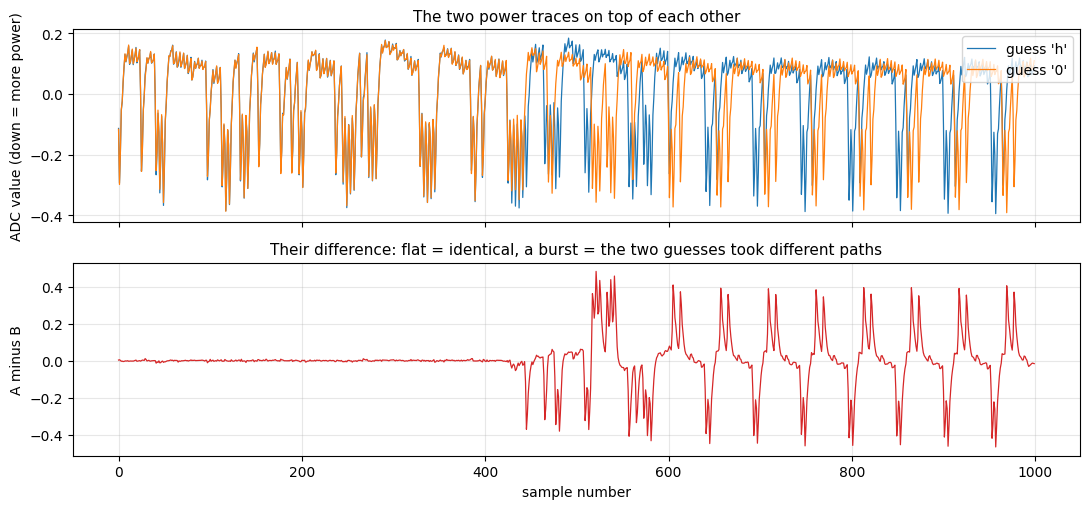

total difference between the two traces: 301.2


In [3]:
# ✏️ EDIT THESE
GUESS_A = "h"          # the first guess (without the newline)
GUESS_B = "0"          # the second guess
START, END = 0, 1000   # zoom window, in samples (the whole trace is 0 to 3000)
SMOOTH = 1             # smoothing width: 1 = raw samples, bigger = smoother

a, b = get_trace(GUESS_A), get_trace(GUESS_B)
fig, axes = plt.subplots(2, 1, figsize=(11, 5.2), sharex=True)
x = np.arange(START, END)
axes[0].plot(x, moving_average(a, SMOOTH)[START:END], lw=0.9, label="guess " + repr(GUESS_A))
axes[0].plot(x, moving_average(b, SMOOTH)[START:END], lw=0.9, label="guess " + repr(GUESS_B))
axes[0].legend(loc="upper right"); axes[0].set_ylabel("ADC value (down = more power)")
axes[0].set_title("The two power traces on top of each other")
axes[1].plot(x, (moving_average(a, SMOOTH) - moving_average(b, SMOOTH))[START:END], color="tab:red", lw=0.9)
axes[1].set_ylabel("A minus B"); axes[1].set_xlabel("sample number")
axes[1].set_title("Their difference: flat = identical, a burst = the two guesses took different paths")
plt.tight_layout(); plt.show()
print("total difference between the two traces: {:.1f}".format(score(a, b)))

## Step 2 - Where do a right and a wrong guess split?

To understand the leak, let's be the lab designer for a moment: we **know** the password (the simulator's is `h0px3`), so we can compare a right guess with a wrong one **one character at a time** and find the exact sample where the two traces stop matching.

For each position `k` we compare:

* the **right** prefix - the first `k+1` characters of the password, against
* the **wrong** one - the first `k` characters followed by `\x01` (a byte that is never part of a password).

`first_divergence()` averages a few captures of each to calm the noise, then reports the first sample where they differ by more than `THRESHOLD`.

**Try:**

1. Run it. Look at the five sample numbers. How far apart are they? *(Each extra correct character pushes the split later by the same amount.)*
2. Set `THRESHOLD = 0.2`, then `0.01`. How do the numbers move? What does that tell you about the "exact" split sample?
3. Set `AVERAGES = 1`. Is the result still good? (The recorded traces are very clean.)
4. On **your own chip** with a changed password, set `STUDY_PASSWORD` to that password.

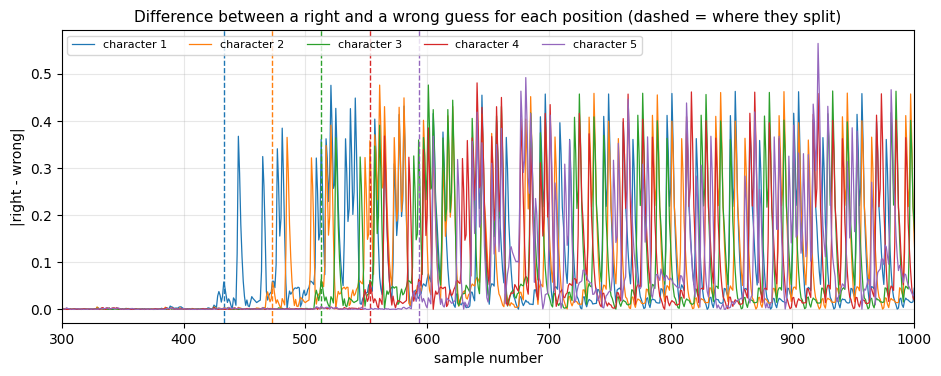

position | right guess -> wrong guess              | traces split at sample | later than the previous by
       1 |      'h' -> '\x01'                         |                    433 |           
       2 |     'h0' -> 'h\x01'                        |                    473 |         40
       3 |    'h0p' -> 'h0\x01'                       |                    513 |         40
       4 |   'h0px' -> 'h0p\x01'                      |                    553 |         40
       5 |  'h0px3' -> 'h0px\x01'                     |                    593 |         40


In [4]:
# ✏️ EDIT THESE
STUDY_PASSWORD = "h0px3"    # the password we study. Simulator: h0px3.  Your own firmware: whatever you set it to.
THRESHOLD = 0.05            # a difference bigger than this (in ADC units) counts as "the traces have split"
AVERAGES = 10               # how many captures to average for each trace
SMOOTH_DIFF = 1             # smoothing applied to the difference before looking for the split (1 = none)


def first_divergence(good, bad, threshold=0.05, smooth_width=1):
    '''First sample where |good - bad| (after optional smoothing) is bigger than `threshold`; None if it never is.'''
    d = np.abs(moving_average(np.asarray(good) - np.asarray(bad), smooth_width))
    idx = np.nonzero(d > threshold)[0]
    return int(idx[0]) if len(idx) else None


splits, diffs = [], []
for k in range(len(STUDY_PASSWORD)):
    right = get_trace(STUDY_PASSWORD[: k + 1], AVERAGES)
    wrong = get_trace(STUDY_PASSWORD[:k] + "\x01", AVERAGES)
    splits.append(first_divergence(right, wrong, THRESHOLD, SMOOTH_DIFF))
    diffs.append(np.abs(right - wrong))

fig, ax = plt.subplots(figsize=(11, 3.8))
for k, (d, s) in enumerate(zip(diffs, splits)):
    line, = ax.plot(d, lw=0.9, label="character {}".format(k + 1))
    if s is not None:
        ax.axvline(s, color=line.get_color(), ls="--", lw=1)
ax.set_xlabel("sample number"); ax.set_ylabel("|right - wrong|"); ax.set_xlim(300, 1000)
ax.set_title("Difference between a right and a wrong guess for each position (dashed = where they split)")
ax.legend(fontsize=8, ncol=5, loc="upper left"); plt.show()

print("position | right guess -> wrong guess              | traces split at sample | later than the previous by")
for k, s in enumerate(splits):
    step = "" if k == 0 or s is None or splits[k - 1] is None else s - splits[k - 1]
    print("{:8d} | {:>8} -> {:<30} | {:>22} | {:>10}".format(
        k + 1, repr(STUDY_PASSWORD[: k + 1]), repr(STUDY_PASSWORD[:k] + "\x01"), "never" if s is None else s, step))

**How long is 40 samples?** The **time** per character is fixed - what changes with the capture settings is how many *samples* that time covers. In Lab 2_1A the Husky took **4 samples per clock cycle**, so 40 samples would be **10 clock cycles** - one more comparison inside the checker's loop. The recorded traces here come from a different capture setup (their autocorrelation shows no clear clock pattern), so this notebook counts in **samples**. On your own chip you can measure samples per cycle with the Lab 2_1A Explorer, Step 2.

## Step 3 - Score every possible character

Now the real attack: we **don't** know the password. To find the first character, try every possible character, compare each trace with a wrong-guess reference (`\x01`), and give each a **score** (how different it is from the reference). The right character takes the other path, so it scores far higher than all the wrong ones.

You choose three things:

| Setting | Meaning |
|---|---|
| `WINDOW_START, WINDOW_END` | Which samples to compare. Samples outside the window are ignored. |
| `METRIC` | How to turn the difference into one number: `'sum_abs'` (add up the size of every difference), `'sum_sq'` (add up squares - big differences count extra) or `'max_abs'` (just the single biggest difference). |
| `REPEATS` | How many captures to average for each guess (more = less noise, but more captures). |

**Try:**

1. Run it with the defaults. Which character wins? By how many times its nearest rival (the `margin`)?
2. Set `KNOWN_PREFIX = "h"` - you are now finding the **second** character. Then `"h0"`, `"h0p"`...
3. Narrow the window to `400, 500`. Does it still work? What about `0, 300`? *(Where does the split happen for the first character? Step 2 told you.)*
4. Switch `METRIC` and compare the margins.

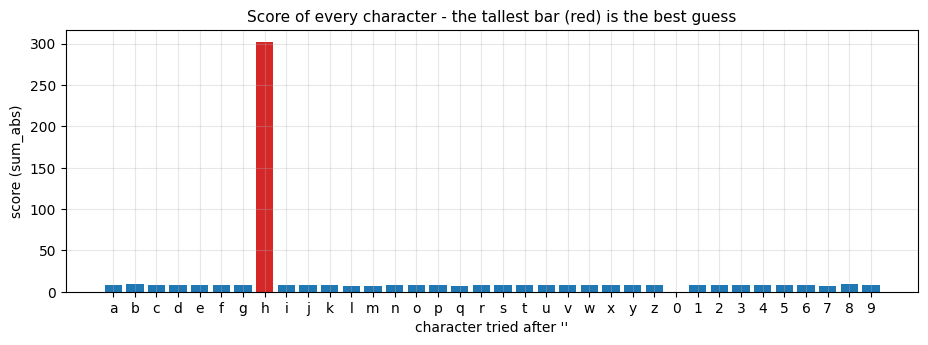

best character: 'h' (score 301.4) | runner-up: 'b' (9.4) | margin: 32.2x


In [5]:
# ✏️ EDIT THESE
KNOWN_PREFIX = ""                  # the characters you have already found (start with "")
WINDOW_START, WINDOW_END = 0, 3000 # which samples to compare
METRIC = "sum_abs"                 # 'sum_abs', 'sum_sq' or 'max_abs'
REPEATS = 1                        # captures averaged per guess

ref, scores = score_all(KNOWN_PREFIX, WINDOW_START, WINDOW_END, METRIC, REPEATS)
ranked = sorted(scores.items(), key=lambda t: -t[1])
(best_c, best_s), (second_c, second_s) = ranked[0], ranked[1]

fig, ax = plt.subplots(figsize=(11, 3.4))
ax.bar(list(CHARSET), [scores[c] for c in CHARSET], color=["tab:red" if c == best_c else "tab:blue" for c in CHARSET])
ax.set_xlabel("character tried after {}".format(repr(KNOWN_PREFIX))); ax.set_ylabel("score ({})".format(METRIC))
ax.set_title("Score of every character - the tallest bar (red) is the best guess")
plt.show()
print("best character: {!r} (score {:.1f}) | runner-up: {!r} ({:.1f}) | margin: {:.1f}x".format(
    best_c, best_s, second_c, second_s, best_s / second_s if second_s else float("inf")))

## Step 4 - Run the whole attack

Repeat Step 3 for position 1, then 2, then 3... each time adding the character that scored highest to the password found so far. **Five rounds of 36 guesses** instead of trying every possible 5-character password.

**Try:**

1. Run it with the defaults. Read the recovered password and look at how many captures it used.
2. Set `ATTACK_END = 500`. Which characters does it still get right? Why does it go wrong from the third character on? *(Hint: the split moves 40 samples later for every correct character - see Step 2.)*
3. Try each `METRIC`, then `REPEATS = 2`. Is the answer different? What does it cost?
4. Look at the little charts: in every round exactly one bar should tower over the rest. In which round is the margin smallest?

round 1: 'h'


round 2: 'h0'


round 3: 'h0p'


round 4: 'h0px'


round 5: 'h0px3'


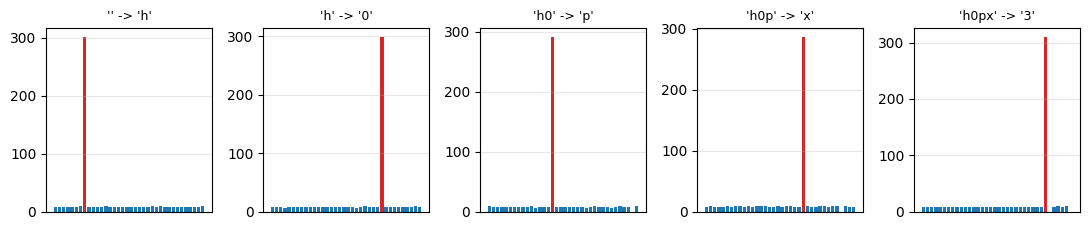

recovered password: 'h0px3'
captures used: 185 (in 16 s)
brute force would need up to 60,466,176 guesses; the power attack used 185 - about 326,844 times fewer.
the simulator's hidden password is 'h0px3' -> MATCH


In [6]:
# ✏️ EDIT THESE
PASSWORD_LENGTH = 5                  # how many characters the password has
ATTACK_START, ATTACK_END = 0, 3000   # which samples to compare
ATTACK_METRIC = "sum_abs"            # 'sum_abs', 'sum_sq' or 'max_abs'
ATTACK_REPEATS = 1                   # captures averaged per guess

found, rounds, captures = "", [], 0
t0 = time.time()
for r in range(PASSWORD_LENGTH):
    ref, scores = score_all(found, ATTACK_START, ATTACK_END, ATTACK_METRIC, ATTACK_REPEATS)
    captures += (len(CHARSET) + 1) * ATTACK_REPEATS
    best = max(scores, key=scores.get)
    rounds.append((found, scores, best))
    found += best
    print("round {}: {!r}".format(r + 1, found))

fig, axes = plt.subplots(1, PASSWORD_LENGTH, figsize=(11, 2.4), sharey=False)
for ax, (prefix, scores, best) in zip(np.atleast_1d(axes), rounds):
    ax.bar(range(len(CHARSET)), [scores[c] for c in CHARSET], color=["tab:red" if c == best else "tab:blue" for c in CHARSET])
    ax.set_title("{!r} -> {!r}".format(prefix, best), fontsize=9); ax.set_xticks([])
plt.tight_layout(); plt.show()

brute = len(CHARSET) ** PASSWORD_LENGTH
print("recovered password: {!r}".format(found))
print("captures used: {} (in {:.0f} s)".format(captures, time.time() - t0))
print("brute force would need up to {:,} guesses; the power attack used {:,} - about {:,.0f} times fewer.".format(brute, captures, brute / captures))
if VERSION == 'SIMULATED':
    print("the simulator's hidden password is 'h0px3' ->", "MATCH" if found == "h0px3" else "different (the attack failed with these settings)")

## Step 5 - What breaks the attack? Noise - and what fixes it

The recorded traces are extremely clean. A real chip next to a noisy power supply is not. Let's **turn the noise up** and see when the attack stops working.

To do that many times quickly, we build a **model from real traces**: for each position we capture one clean "right" trace and one clean "wrong" trace (averaged), then add random noise to each simulated capture. Averaging `R` captures reduces the noise by a factor of `sqrt(R)`, so the model uses a smaller noise for repeats. Each cell of the grid below runs the whole attack `TRIALS` times and counts how often it recovers the full password.

> ⚠️ **This is a model built from real data, not a new measurement.** It is the right tool for asking "how much noise can the attack take?", not for predicting your own chip's exact numbers.

**Try:**

1. Run it as it is. Read across the first row (single captures): at what noise level does the attack start to fail?
2. Read down a column: how does averaging more captures help? Roughly how much extra averaging buys you each doubling of the noise?
3. Edit `NOISE_LEVELS` and `REPEAT_LEVELS` to zoom in on the edge of the green area.
4. Narrow `MODEL_WINDOW` to `(0, 1000)`. Does the attack tolerate as much noise? *(A bigger window collects more signal.)*

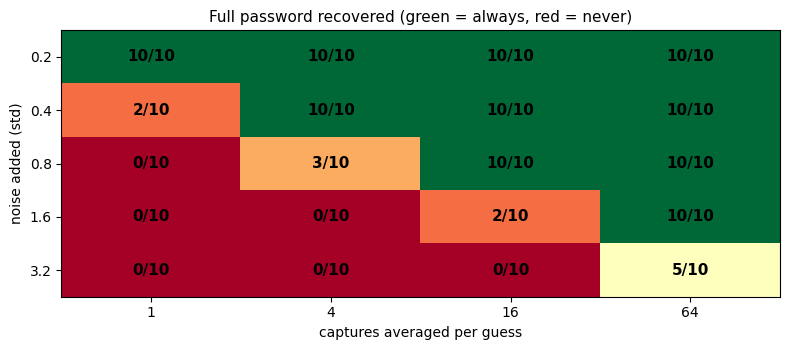

In [7]:
# ✏️ EDIT THESE
STUDY_PASSWORD = "h0px3"                  # the password in the model (simulator: h0px3)
NOISE_LEVELS = [0.2, 0.4, 0.8, 1.6, 3.2]  # standard deviation of the noise added to every sample (the real recordings: about 0.003)
REPEAT_LEVELS = [1, 4, 16, 64]            # captures averaged per guess
TRIALS = 10                               # how many full attacks to run for each cell
MODEL_WINDOW = (0, 3000)                  # samples compared (start, end)
MODEL_METRIC = "sum_abs"

# --- build the model library from real traces: for each position one 'right' and one 'wrong' average (nothing to edit) ---
LIBRARY = {}
for k in range(len(STUDY_PASSWORD)):
    LIBRARY[("wrong", k)] = get_trace(STUDY_PASSWORD[:k] + "\x01", 10)
    LIBRARY[("right", k)] = get_trace(STUDY_PASSWORD[: k + 1], 10)
rng = np.random.default_rng(1)


def model_capture(kind, k, noise, repeats=1, jitter=0, window=(0, 3000)):
    '''One simulated (averaged) capture. `kind` is 'right' or 'wrong' for position k.'''
    a, b = window
    base = LIBRARY[(kind, k)]
    if jitter:
        t = np.mean([np.roll(base, int(rng.integers(-jitter, jitter + 1))) + rng.normal(0, noise, base.shape)
                     for _ in range(repeats)], axis=0)
    else:
        t = base + rng.normal(0, noise / np.sqrt(repeats), base.shape)
    return t[a:b]


def model_attack(noise, repeats, window=(0, 3000), metric="sum_abs", jitter=0):
    '''Run the whole attack on the model. Returns the recovered password.'''
    found = ""
    for k in range(len(STUDY_PASSWORD)):
        ref = model_capture("wrong", k, noise, repeats, jitter, window)
        scores = {}
        for c in CHARSET:
            kind = "right" if c == STUDY_PASSWORD[k] else "wrong"
            scores[c] = score(model_capture(kind, k, noise, repeats, jitter, window), ref, 0, window[1] - window[0], metric)
        found += max(scores, key=scores.get)
    return found


wins = np.array([[sum(model_attack(n, r, MODEL_WINDOW, MODEL_METRIC) == STUDY_PASSWORD for _ in range(TRIALS))
                  for r in REPEAT_LEVELS] for n in NOISE_LEVELS])
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.imshow(wins, cmap="RdYlGn", vmin=0, vmax=TRIALS, aspect="auto"); ax.grid(False)
ax.set_xticks(range(len(REPEAT_LEVELS))); ax.set_xticklabels(REPEAT_LEVELS); ax.set_xlabel("captures averaged per guess")
ax.set_yticks(range(len(NOISE_LEVELS))); ax.set_yticklabels(NOISE_LEVELS); ax.set_ylabel("noise added (std)")
for i in range(len(NOISE_LEVELS)):
    for j in range(len(REPEAT_LEVELS)):
        ax.text(j, i, "{}/{}".format(wins[i, j], TRIALS), ha="center", va="center", fontsize=11, fontweight="bold")
ax.set_title("Full password recovered (green = always, red = never)")
plt.tight_layout(); plt.show()

## Step 6 - A defence: random delays

A well-known defence is to make the chip wait a **random** time before it does the check. Then the same guess gives a trace that is **shifted** by a different amount every time. Our scoring compares samples at the *same position*, so a shift makes even identical guesses look different.

The cell below shifts every simulated capture left or right by a random number of samples between `-JITTER` and `+JITTER`. Like Step 5 it runs the whole attack several times for each combination of **delay size** (rows) and **captures averaged per guess** (columns).

**Try:**

1. Run it as it is. With a **single capture** (first column), how big a random delay does it take to break the attack?
2. Look along a row: how much does averaging more captures help against a delay of 4 samples? Of 8? Of 16?
3. Are there delays that even 16 averages cannot beat? What would the attacker have to do instead? *(Think about what the shifted traces no longer do.)*
4. Change `SHOW_JITTER` and look at the left charts: what happens to the scores of the *wrong* characters when the delay gets large? And in the right chart, why do the five copies of the same guess no longer sit on top of each other?

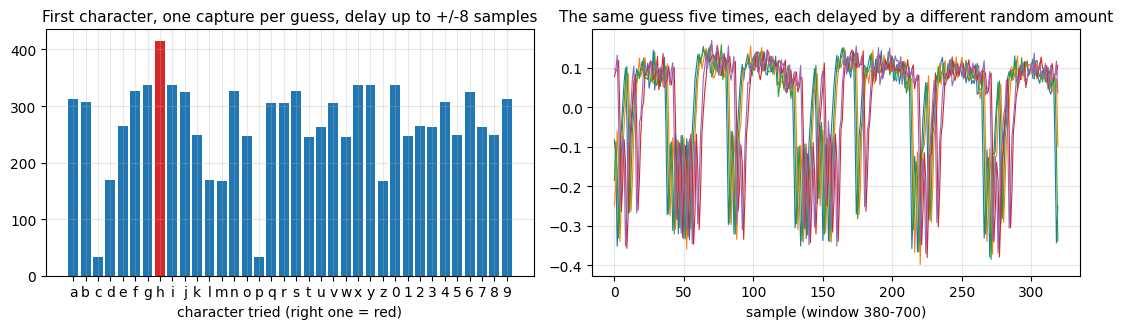

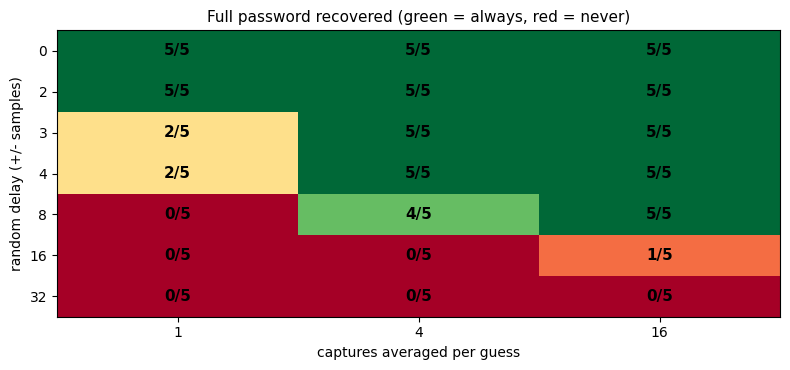

In [8]:
# ✏️ EDIT THESE
JITTER_LEVELS = [0, 2, 3, 4, 8, 16, 32]   # random delay: shift each capture by up to +/- this many samples
JITTER_REPEATS = [1, 4, 16]               # captures averaged per guess
JITTER_NOISE = 0.01                       # a little ordinary noise as well
JITTER_TRIALS = 5                         # full attacks per cell
SHOW_JITTER = 8                           # the delay used for the two example charts

# example charts for one delay: scores of the first character, and five shifted copies of the same guess
a, b = MODEL_WINDOW
ref = model_capture("wrong", 0, JITTER_NOISE, 1, SHOW_JITTER, MODEL_WINDOW)
sc = {c: score(model_capture("right" if c == STUDY_PASSWORD[0] else "wrong", 0, JITTER_NOISE, 1, SHOW_JITTER, MODEL_WINDOW),
               ref, 0, b - a, "sum_abs") for c in CHARSET}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].bar(list(CHARSET), [sc[c] for c in CHARSET], color=["tab:red" if c == STUDY_PASSWORD[0] else "tab:blue" for c in CHARSET])
axes[0].set_title("First character, one capture per guess, delay up to +/-{} samples".format(SHOW_JITTER)); axes[0].set_xlabel("character tried (right one = red)")
for _ in range(5):
    axes[1].plot(model_capture("wrong", 0, JITTER_NOISE, 1, SHOW_JITTER, (380, 700)), lw=0.8)
axes[1].set_title("The same guess five times, each delayed by a different random amount"); axes[1].set_xlabel("sample (window 380-700)")
plt.tight_layout(); plt.show()

# the grid: delay size x averaging
wins = np.array([[sum(model_attack(JITTER_NOISE, r, MODEL_WINDOW, "sum_abs", j) == STUDY_PASSWORD for _ in range(JITTER_TRIALS))
                  for r in JITTER_REPEATS] for j in JITTER_LEVELS])
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.imshow(wins, cmap="RdYlGn", vmin=0, vmax=JITTER_TRIALS, aspect="auto"); ax.grid(False)
ax.set_xticks(range(len(JITTER_REPEATS))); ax.set_xticklabels(JITTER_REPEATS); ax.set_xlabel("captures averaged per guess")
ax.set_yticks(range(len(JITTER_LEVELS))); ax.set_yticklabels(JITTER_LEVELS); ax.set_ylabel("random delay (+/- samples)")
for i in range(len(JITTER_LEVELS)):
    for j in range(len(JITTER_REPEATS)):
        ax.text(j, i, "{}/{}".format(wins[i, j], JITTER_TRIALS), ha="center", va="center", fontsize=11, fontweight="bold")
ax.set_title("Full password recovered (green = always, red = never)")
plt.tight_layout(); plt.show()

So a small **random delay** only raises the price: the attacker needs several times more captures. A **large** delay makes plain averaging useless, and then the attacker has to **re-align** every trace (line it up again, for example on a recognisable feature) before comparing - which is the subject of later labs. Other defences are even simpler: compare the whole password in **constant time**, or **limit the number of wrong guesses** the device accepts.

## Step 7 - Run it on your own chip (hardware)

Everything above except the model steps works unchanged on the real chip, because both back-ends give you the same `cap_pass_trace()` function.

1. Assemble the Husky kit as in Lab 0 and plug it in (check the **SAM4S** target board is the one mounted).
2. In the first cell set `VERSION = 'HARDWARE'` and choose **Kernel > Restart & Run All**. The Setup cell builds and flashes `basic-passwdcheck` for you.
3. Close any other notebook that is connected to the Husky: only one program can hold it.
4. Re-run Steps 1 to 4. Step 4 now makes about 185 real captures (each takes a fraction of a second) - give it a minute or two.
5. Steps 5 and 6 build their model from your **live** traces, so they work too (they take longer to set up).

**Experiments - predict first, then run:**

| Change | What do you predict? |
|---|---|
| Step 2 with your own chip | Is the split-to-split gap still the same number of samples? |
| Step 3 `REPEATS = 1` then `4` | Is your chip noisier than the recorded traces? |
| Change the password in the firmware (see the companion notebook *Lab 2_1B - Firmware Change and Flash Walkthrough*), set `STUDY_PASSWORD` to it, set `PASSWORD_LENGTH` to its length, run Step 4 | Does the attack find your new password? |

In [9]:
if VERSION != 'HARDWARE':
    print("This notebook is running in SIMULATED mode. To try your own chip, set VERSION = 'HARDWARE' in the Setup cell")
    print("(with the Husky kit connected) and choose Kernel > Restart & Run All.")
else:
    print("HARDWARE mode: all captures in the steps above came from your own chip.")
    print("Time one capture:")
    t0 = time.time(); get_trace("h"); print("   one capture took {:.2f} s -> the full attack in Step 4 needs about {:.0f} s".format(
        time.time() - t0, 185 * (time.time() - t0)))

This notebook is running in SIMULATED mode. To try your own chip, set VERSION = 'HARDWARE' in the Setup cell
(with the Husky kit connected) and choose Kernel > Restart & Run All.


## Step 8 - Check your understanding

Try each question yourself first - the answers are in the next cell.

1. Why does a right first character look different from a wrong one in the power trace?
2. How much later does the split happen for each extra correct character? What is that time, in samples - and in clock cycles if the capture takes 4 samples per cycle?
3. Why did the attack with `ATTACK_END = 500` get the first two characters but fail after that?
4. How many guesses does brute force need for a 5-character password made of 36 possible characters? How many captures did the power attack use?
5. Why does averaging more captures rescue the attack when the noise goes up? What does it cost?
6. Why does a small random delay break the single-capture attack? What does averaging do about it, and when does that stop working?
7. Name two ways a designer could stop this attack.

### Answers

1. The checker stops at the first wrong character. With a right character it carries on to compare the next one, so it executes **different code for longer** - which draws a different amount of power over time.
2. The split moves **40 samples** later per correct character (samples 433, 473, 513, 553, 593 in the recorded traces). That is the time of one more comparison; if your capture takes 4 samples per clock cycle (as the Husky's default setup does in Lab 2_1A) it is **10 clock cycles**.
3. The window stops at sample 500, but the split for the *third* character is at about 513 and later ones even further. Outside the window the traces look identical, so every wrong character scores about the same and the attack picks one at random. **The window must reach past the split point, which moves later with each correct character.**
4. **36^5 = 60,466,176** guesses in the worst case. The power attack used **185** captures (5 rounds of 36 guesses plus 5 references) - hundreds of thousands of times fewer.
5. Noise adds random values to every sample; averaging `R` captures cancels most of it - the noise shrinks by `sqrt(R)`. The price is `R` times as many captures (and time). The grid shows that each 4x increase in averaging lets the attack survive about 2x more noise.
6. A random shift means identical guesses no longer line up sample by sample, so their *difference* is large even when the guess is wrong, burying the real signal - a delay of about 3 samples already breaks the single-capture attack. Because every shift is random and independent, **averaging 4 to 16 captures** blurs them into a smooth average in which the right guess still stands out (up to about 8 samples of delay in the model). Delays of 16 samples or more are bigger than the features in the trace; even 16 averages barely help (0 or 1 successes in 5 in the model), and the attacker has to **re-align** the traces first.
7. For example: compare the whole password in **constant time** (never stop early); add **random delays** (plus an attacker will need re-alignment); **limit wrong attempts** or lock out; hide or mask the check in hardware.

## Conclusions & Next Steps

You have now found where a right and a wrong guess split, measured that each correct character pushes the split 40 samples later, scored every character, run the whole attack, and broken it with noise and random delays. The idea - **the time a chip spends depends on secret data** - is the foundation of everything in SCA101. In the next labs you will go from "how long" to "how much power": the *value* of the data being processed changes the power, and that is how AES keys are recovered.

---
<small>NO-FUN DISCLAIMER: This material is Copyright (C) NewAE Technology Inc., 2015-2020. ChipWhisperer is a trademark of NewAE Technology Inc., claimed in all jurisdictions, and registered in at least the United States of America, European Union, and Peoples Republic of China.

Tutorials derived from our open-source work must be released under the associated open-source license, and notice of the source must be *clearly displayed*. Only original copyright holders may license or authorize other distribution - while NewAE Technology Inc. holds the copyright for many tutorials, the github repository includes community contributions which we cannot license under special terms and **must** be maintained as an open-source release. Please contact us for special permissions (where possible).

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY, FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM, OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE SOFTWARE.</small>